# Task5 — Subspace Cluster Audit

ตรวจกลุ่มเล็กที่อาจถูกมองข้ามด้วย clustering แยกมุมพฤติกรรม และเทียบกับผลเดิมของเรา

**ไม่สร้าง anomaly predictions หรือไฟล์ส่ง Kaggle**. Cluster, noise, stability และ baseline coverage ไม่ใช่ground-truth anomaly labels.
ค่าเริ่มต้น Run All โหลดผลที่ทำเสร็จ

## 1. Setup

In [1]:
from pathlib import Path
import sys,os,json
os.environ.setdefault("LOKY_MAX_CPU_COUNT","4")
ROOT=next((p for q in [Path.cwd(),*Path.cwd().parents] for p in [q,q/"CPE342-Kaggle"] if (p/"Task5/models/subspace_cluster_audit.py").exists()),None)
if ROOT is None:raise FileNotFoundError("เปิด notebook ภายใน CPE342-Kaggle")
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
import pandas as pd
from IPython.display import display,Image
from Task5.models import subspace_cluster_audit as study
RUN_FITS=False
RUN_VERIFICATION=False
print(ROOT)

/Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle


## 2. Four Subspaces & Prespecified Stability Rules

In [2]:
raw,spaces=study.initialize()
display(pd.DataFrame([{"space":k,"dimensions":v.shape[1],"families":", ".join(study.FAMILIES[k])} for k,v in spaces.items()]))
display(pd.Series(study.CONFIG))

,space,dimensions,families
0,routine,12,"login_count, session_duration_mean, session_du..."
1,access,11,"device_count, location_changes, ip_hash_entrop..."
2,economy,10,"purchase_frequency, purchase_amount_mean, purc..."
3,transitions,21,"login_count, device_count, location_changes, a..."


views                                 [raw_robust, asinh_robust]
min_cluster_sizes                                      [40, 120]
min_samples                                                   15
cluster_selection_method                                    leaf
subsample_fraction                                           0.8
resample_seeds                                   [111, 222, 333]
threads                                                        4
stable_min_median_resample_jaccard                           0.7
stable_min_worst_resample_jaccard                            0.5
stable_min_cross_view_jaccard                                0.5
small_cluster_max_fraction                                  0.05
dtype: object

Routine: mean/std of six activity/time families. Access/economy: mean/max-adjacent-change; access adds geodesic max distance. Transitions: three Haar contrasts across four periods for seven families.

Robust median/IQR scaling either on original features or after asinh compression. No UMAP, uniform-rank mapping or clipping. Missing values are median-imputed; inspect missingness artifacts separately. IDs/security flags do not enter clustering; flags may appear in descriptive profiles, never as labels.

HDBSCAN leaf selection, min_cluster_size40/120 and min_samples15. Full16fits +48subsamplefits. For80% subsamples, minimum sizes scale proportionally; imputation/scaling refit on each sample. HDBSCAN itself is deterministic for fixed inputs here; seeds change sampled rows.

Predeclared review rule: cluster ≤5% of accounts, median resample Jaccard≥.70, worst resample Jaccard≥.50, cross-scaling Jaccard≥.50. Compare membership on shared sampled rows, match by maximum Jaccard; merges/splits reduce overlap. These thresholds select reproducible groups, not anomalies

## 3. Fit / Resume

In [3]:
if RUN_FITS:study.fit_all()
else:assert (study.OUT/"summary.json").exists(),"เปิด RUN_FITS หากยังไม่มีผล"
display(pd.Series(json.loads((study.OUT/"summary.json").read_text())))

accounts                                                                  25889
full_runs                                                                    16
resample_runs                                                                48
cluster_instances                                                            60
stable_small_instances                                                       17
deduplicated_review_groups                                                    6
union_review_accounts                                                       959
prediction_csv_created                                                    False
anomaly_labels_available                                                  False
interpretation                Stable clusters are descriptive groups, not va...
dtype: object

## 4. What Cluster Structure Exists?

,space,view,size,sample,rows,clusters,noise,seconds
0,routine,raw_robust,40,full,25889,2,14939,2.123626
1,routine,raw_robust,120,full,25889,0,25889,1.188324
2,routine,asinh_robust,40,full,25889,3,257,1.184932
3,routine,asinh_robust,120,full,25889,2,34,1.188565
4,access,raw_robust,40,full,25889,7,18707,1.373960
5,access,raw_robust,120,full,25889,4,18689,1.383007
6,access,asinh_robust,40,full,25889,5,15597,1.789061
7,access,asinh_robust,120,full,25889,5,15597,1.612293
8,economy,raw_robust,40,full,25889,4,4781,1.463441
9,economy,raw_robust,120,full,25889,4,4781,1.427775


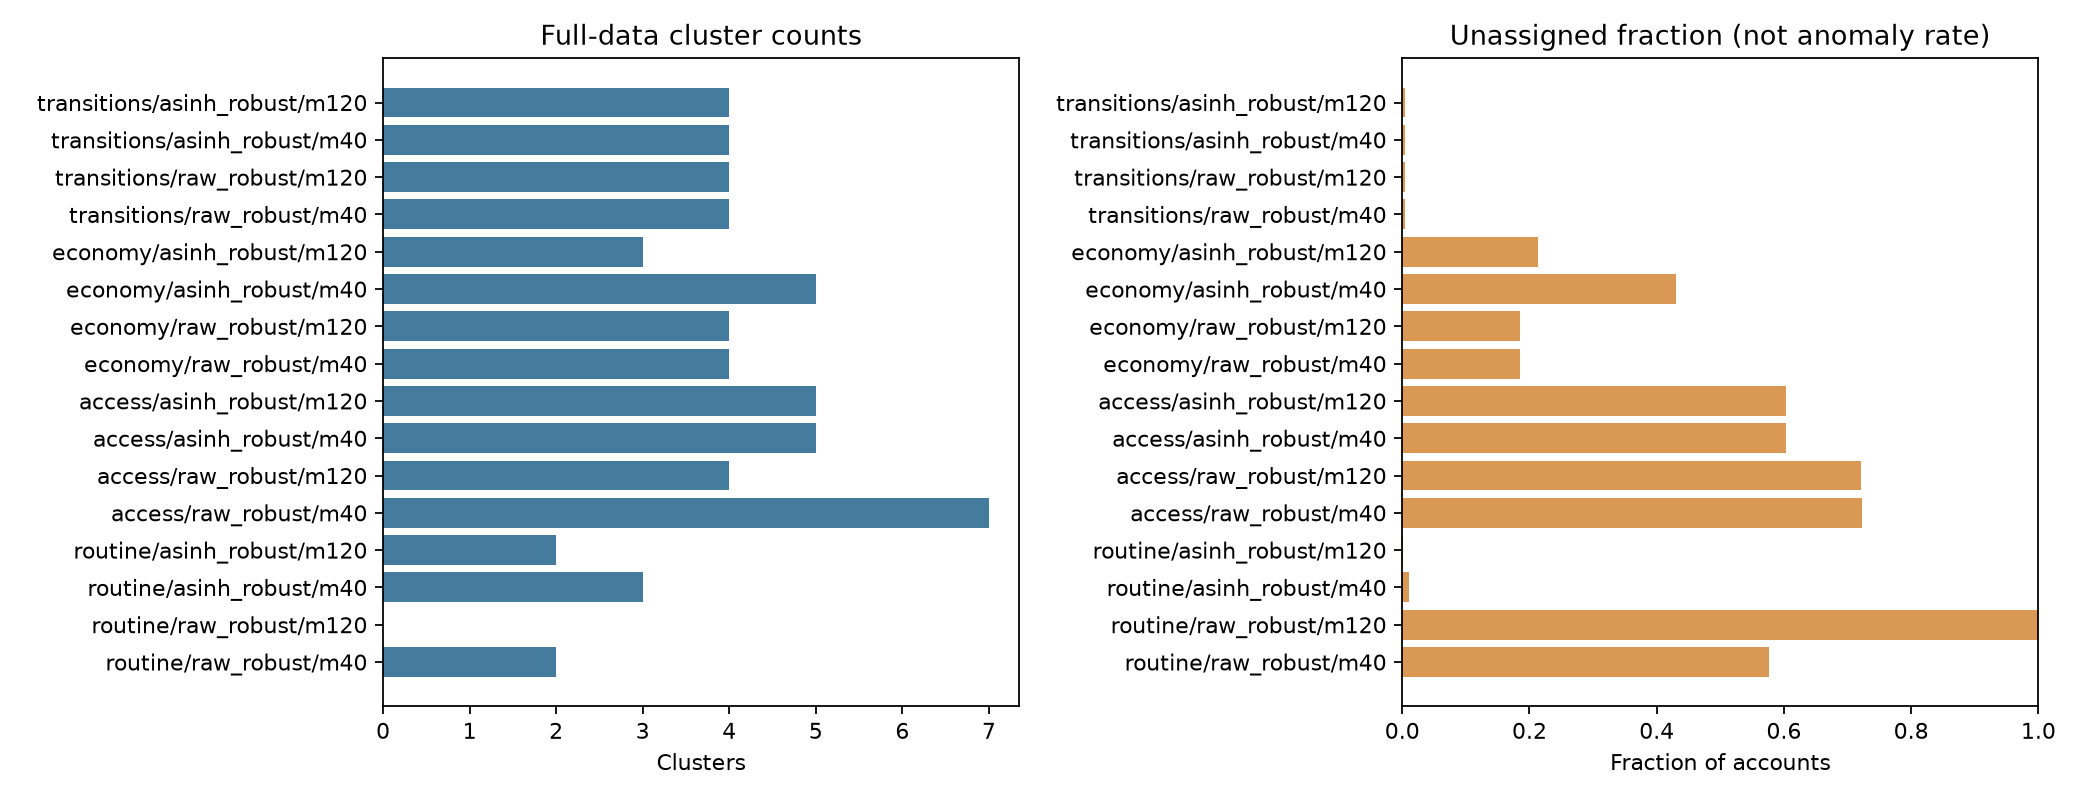

In [4]:
runs=pd.read_parquet(study.OUT/"runs.parquet")
display(runs)
display(Image(filename=str(study.OUT/"figures/run_overview.png")))

Noise=-1 คือHDBSCANไม่จัดเข้ากลุ่มภายใต้recipeนี้ ไม่ใช่บัญชีโกง. จำนวนclustersมากขึ้นหรือnoiseมากขึ้นไม่ใช่คะแนนที่ดีกว่า

## 5. Cluster Reproducibility

,cluster_id,accounts,resample_jaccard_median,resample_jaccard_min,cross_view_jaccard,alternate_min_size_jaccard,stable_small
48,transitions__raw_robust__m120__c0,272,1.000000,0.995349,0.985507,1.000000,True
53,transitions__asinh_robust__m40__c1,25152,1.000000,0.999950,0.997416,1.000000,False
2,routine__asinh_robust__m40__c0,207,1.000000,1.000000,0.429952,1.000000,False
57,transitions__asinh_robust__m120__c1,25152,1.000000,0.999950,0.997416,1.000000,False
5,routine__asinh_robust__m120__c0,207,1.000000,1.000000,0.000000,1.000000,False
19,access__asinh_robust__m40__c1,206,1.000000,1.000000,0.985507,1.000000,True
56,transitions__asinh_robust__m120__c0,276,1.000000,1.000000,0.985507,1.000000,True
24,access__asinh_robust__m120__c1,206,1.000000,1.000000,0.985507,1.000000,True
52,transitions__asinh_robust__m40__c0,276,1.000000,1.000000,0.985507,1.000000,True
47,transitions__raw_robust__m40__c3,25087,0.999950,0.999950,0.997416,1.000000,False


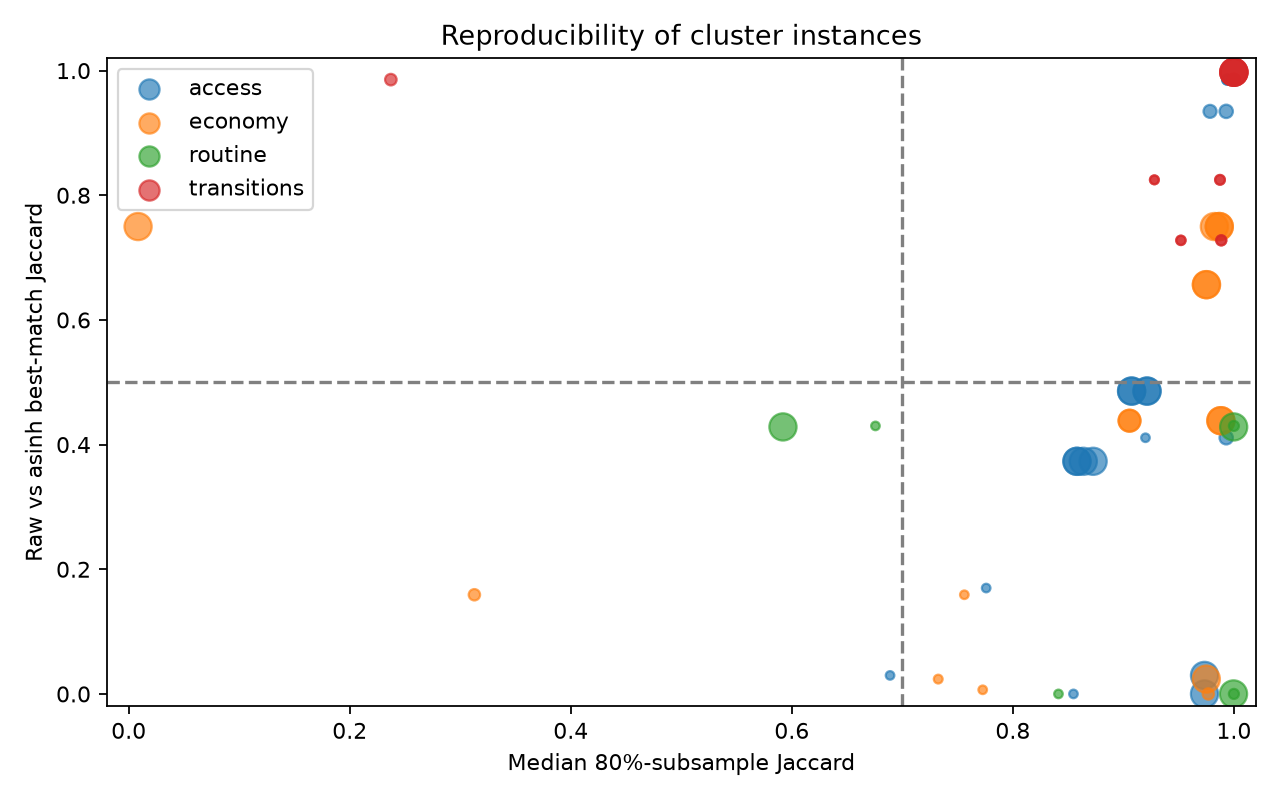

In [5]:
clusters=pd.read_parquet(study.OUT/"clusters.parquet")
display(clusters[["cluster_id","accounts","resample_jaccard_median","resample_jaccard_min","cross_view_jaccard","alternate_min_size_jaccard","stable_small"]].sort_values("resample_jaccard_median",ascending=False))
if (study.OUT/"figures/stability.png").exists():display(Image(filename=str(study.OUT/"figures/stability.png")))

## 6. Baseline Comparison — No Pseudo-labels

,name,reported_overall_public_score,sha256
0,density_auto_v1,0.81771,cd5725c7e9994d60a05ad31f917107d92e268f9833c0c6...
1,rank_fusion95_5_v1,0.80678,4e3878630a9d3d02ce14d03824c99295cf1e5e5d4a9613...
2,tail_engineered_v20,0.75893,5eafce98b1eacffc44e74fd682bd3cad4829d44f3ee775...
3,full_family_cap2_v1,0.75552,70bf6ef2497b736518f6b085aae6a562f03a77aaee5abd...
4,multiscale_representation_v1,0.73801,844d1efe84bdb043a6a566d0adfcee76060401b13a887e...
5,behavior_blocks5_v1,0.79798,e2e99a605837dd50eb5583c1824a8b347758118e8f2eff...


,cluster_id,space,view,min_size,cluster,accounts,population_fraction,resample_jaccard_median,resample_jaccard_min,cross_view_jaccard,...,stable_small,mean_raw_missing_count,space_missing_cell_fraction,unique_space_rows,density_auto_v1_coverage,rank_fusion95_5_v1_coverage,tail_engineered_v20_coverage,full_family_cap2_v1_coverage,multiscale_representation_v1_coverage,behavior_blocks5_v1_coverage
0,access__asinh_robust__m40__c1,access,asinh_robust,40,1,206,0.007957,1.000000,1.000000,0.985507,...,True,6.082524,0.002207,206,1.000000,1.000000,1.000000,1.000000,0.936893,1.000000
1,transitions__raw_robust__m120__c0,transitions,raw_robust,120,0,272,0.010506,1.000000,0.995349,0.985507,...,True,5.757353,0.111345,272,1.000000,1.000000,0.996324,0.996324,0.966912,1.000000
2,access__asinh_robust__m120__c0,access,asinh_robust,120,0,365,0.014099,0.993056,0.989831,0.934605,...,True,6.230137,0.003985,365,0.989041,0.989041,0.997260,0.997260,0.991781,0.991781
3,transitions__raw_robust__m40__c1,transitions,raw_robust,40,1,209,0.008073,0.988571,0.982955,0.727679,...,True,5.736842,0.101618,209,0.995215,1.000000,1.000000,1.000000,0.976077,0.995215
4,transitions__raw_robust__m40__c2,transitions,raw_robust,40,2,194,0.007494,0.987421,0.980392,0.824742,...,True,6.247423,0.117084,194,0.984536,0.969072,1.000000,0.989691,0.994845,0.984536
5,transitions__asinh_robust__m40__c3,transitions,asinh_robust,40,3,178,0.006876,0.952055,0.910714,0.727679,...,True,5.623596,0.097646,178,1.000000,1.000000,0.994382,1.000000,0.971910,1.000000


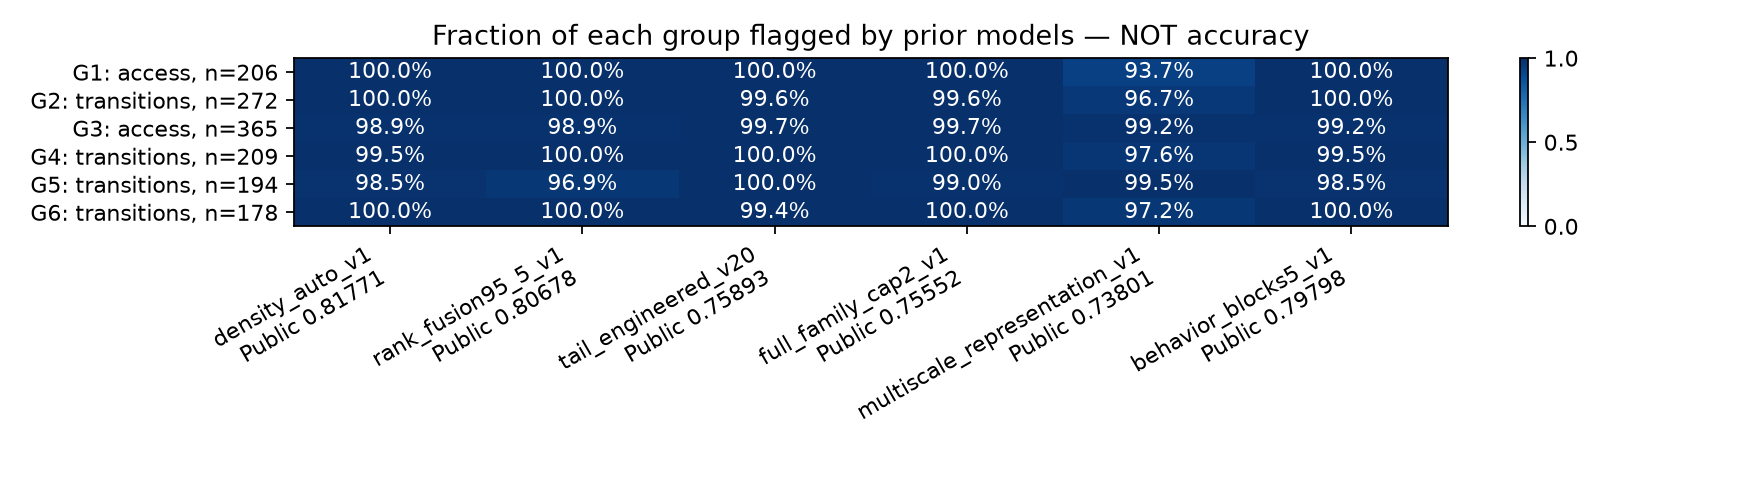

In [6]:
display(pd.DataFrame(json.loads((study.OUT/"baseline_manifest.json").read_text())))
groups=pd.DataFrame(json.loads((study.OUT/"review_groups.json").read_text()))
display(groups)
if (study.OUT/"figures/baseline_coverage.png").exists():display(Image(filename=str(study.OUT/"figures/baseline_coverage.png")))

Baseline coverage = สัดส่วนสมาชิกกลุ่มที่โมเดลเดิมเคยalert. ไม่ใช่precision/recall. คะแนนPublicเป็นคะแนนรวม5tasks.
ดูทั้งตัวดีที่สุดและตัวที่แย่ลง แต่ไม่ใช้ผลเหล่านี้เลือกhyperparametersหรือเปลี่ยนclusterเป็นlabel.
กลุ่มreviewซ้ำกัน≥80%Jaccardถูกdeduplicateโดยใช้stabilityก่อน ไม่ใช้baselinecoverage

## 7. Actual Feature Profiles & Data Quality

In [7]:
profiles=pd.read_parquet(study.OUT/"profiles_contextual.parquet")
context=pd.read_parquet(study.OUT/"review_context.parquet")
if len(groups):
    selected=groups.cluster_id.tolist()
    display(profiles[profiles.cluster_id.isin(selected)])
    display(context)
else:
    print("ไม่มีกลุ่มเล็กผ่านเงื่อนไขครบ; ไม่ผ่อนthresholdเพื่อบังคับให้ได้candidate")

,cluster_id,feature,cluster_median,outside_median,absolute_robust_median_difference,used_for_clustering,same_family_used_for_clustering
228,access__asinh_robust__m40__c1,ip_hash_entropy__mean4,0.104824,0.550070,4.185566,True,True
229,access__asinh_robust__m40__c1,login_time_variance__mean4,0.306195,4.968093,1.541924,True,True
230,access__asinh_robust__m40__c1,play_pattern_consistency__mean4,0.970391,0.747442,1.467373,False,False
231,access__asinh_robust__m40__c1,session_duration_std__mean4,2.947692,24.874390,1.444977,False,False
232,access__asinh_robust__m40__c1,kda_std__mean4,0.100103,0.500138,1.305881,False,False
...,...,...,...,...,...,...,...
667,transitions__asinh_robust__m40__c3,location_changes__mean4,3.705173,1.488060,1.491515,False,True
668,transitions__asinh_robust__m40__c3,device_count__maxstep,2.000000,1.000000,1.000000,False,True
669,transitions__asinh_robust__m40__c3,session_duration_mean__maxstep,41.846357,22.501059,0.855859,False,False
670,transitions__asinh_robust__m40__c3,play_pattern_consistency__mean4,0.641969,0.749396,0.707046,False,False


,cluster_id,accounts,space,password_changed_cluster_mean,password_changed_outside_mean,vpn_usage_cluster_mean,vpn_usage_outside_mean,suspicious_login_time_cluster_mean,suspicious_login_time_outside_mean,mass_item_sale_cluster_mean,mass_item_sale_outside_mean,raw_missing_fraction
0,access__asinh_robust__m40__c1,206,access,0.041451,0.060206,0.190722,0.158870,0.046392,0.050817,0.010152,0.029076,0.049857
1,transitions__raw_robust__m120__c0,272,transitions,0.054475,0.060118,0.149020,0.159227,0.035019,0.050948,0.027451,0.028940,0.047191
2,access__asinh_robust__m120__c0,365,access,0.492582,0.054033,0.604585,0.152718,0.075581,0.050431,0.321739,0.024757,0.051067
3,transitions__raw_robust__m40__c1,209,transitions,1.000000,0.052565,0.196078,0.158813,0.075377,0.050582,0.671642,0.023626,0.047023
4,transitions__raw_robust__m40__c2,194,transitions,0.111111,0.059681,0.924324,0.153330,0.060440,0.050710,0.088889,0.028482,0.051208
5,transitions__asinh_robust__m40__c3,178,transitions,1.000000,0.053459,0.183908,0.158945,0.059172,0.050724,0.664706,0.024497,0.046095


ค่ากลางที่ต่างจากประชากรช่วยอธิบายกลุ่ม ไม่ยืนยันการโจมตี. Featuresที่ใช้clusterย่อมต่างได้โดยconstruction. คอลัมน์used_for_clusteringหมายถึงชื่อfeatureตรงกันเท่านั้น; same_family_used_for_clusteringตรวจว่าเป็นderivedfeatureจากfamilyเดียวกันหรือไม่ จึงไม่ควรถือว่าเป็นหลักฐานอิสระเพียงเพราะชื่อfeatureต่างกัน.
ตรวจmissingness, unique vectors, exact repeated values, invalid coordinatesและrefund=-1ก่อนตีความ. Security flagsที่เห็นในprofileเป็นเพียงตัวแปรประกอบ ไม่ใช่ground truth

## 8. Membership Evidence

In [8]:
display(pd.read_parquet(study.OUT / 'union_baseline_coverage.parquet'))
display(pd.read_parquet(study.OUT / 'unflagged_stable_group_members.parquet'))
display(pd.DataFrame(json.loads((study.OUT / 'feature_ablation.json').read_text())))

,baseline,review_union_accounts,flagged,unflagged,coverage
0,density_auto_v1,959,951,8,0.991658
1,rank_fusion95_5_v1,959,951,8,0.991658
2,tail_engineered_v20,959,957,2,0.997914
3,full_family_cap2_v1,959,956,3,0.996872
4,multiscale_representation_v1,959,930,29,0.969760
5,behavior_blocks5_v1,959,952,7,0.992701


,id,player_id,shift_probability,island_probability,dependence_probability,ranking_score,row_index,density_auto_v1_prediction,rank_fusion95_5_v1_prediction,tail_engineered_v20_prediction,full_family_cap2_v1_prediction,multiscale_representation_v1_prediction,behavior_blocks5_v1_prediction,clusters,membership_strengths,resample_membership_support,cross_view_membership_support
0,ANS03396,P014090,0.0,0.0,0.0,0.000003,3395,0,1,1,1,1,0,transitions__raw_robust__m40__c1,"{""transitions__raw_robust__m40__c1"": 0.7583844...","{""transitions__raw_robust__m40__c1"": {""sampled...","{""transitions__raw_robust__m40__c1"": false}"
1,ANS04289,P020248,0.0,0.0,0.0,0.000003,4288,0,0,1,1,1,0,transitions__raw_robust__m40__c2,"{""transitions__raw_robust__m40__c2"": 0.6910071...","{""transitions__raw_robust__m40__c2"": {""sampled...","{""transitions__raw_robust__m40__c2"": true}"
2,ANS06817,P021920,0.0,0.0,0.0,0.000003,6816,0,1,1,1,1,0,transitions__raw_robust__m40__c2,"{""transitions__raw_robust__m40__c2"": 0.5626607...","{""transitions__raw_robust__m40__c2"": {""sampled...","{""transitions__raw_robust__m40__c2"": false}"
3,ANS08990,P003412,0.0,0.0,0.0,0.000003,8989,0,1,1,1,1,0,access__asinh_robust__m120__c0,"{""access__asinh_robust__m120__c0"": 0.536229237...","{""access__asinh_robust__m120__c0"": {""sampled_r...","{""access__asinh_robust__m120__c0"": true}"
4,ANS12484,P020448,0.0,0.0,0.0,0.000003,12483,0,1,1,1,1,0,access__asinh_robust__m120__c0,"{""access__asinh_robust__m120__c0"": 0.569357297...","{""access__asinh_robust__m120__c0"": {""sampled_r...","{""access__asinh_robust__m120__c0"": true}"
5,ANS18621,P022693,0.0,0.0,0.0,0.000003,18620,0,1,1,1,1,0,access__asinh_robust__m120__c0,"{""access__asinh_robust__m120__c0"": 0.595698949...","{""access__asinh_robust__m120__c0"": {""sampled_r...","{""access__asinh_robust__m120__c0"": true}"
6,ANS21372,P011115,0.0,0.0,0.0,0.000003,21371,0,1,1,1,1,1,access__asinh_robust__m120__c0,"{""access__asinh_robust__m120__c0"": 0.574747891...","{""access__asinh_robust__m120__c0"": {""sampled_r...","{""access__asinh_robust__m120__c0"": true}"
7,ANS23605,P025083,0.0,0.0,0.0,0.000003,23604,0,1,1,1,1,0,transitions__raw_robust__m40__c2,"{""transitions__raw_robust__m40__c2"": 0.8780523...","{""transitions__raw_robust__m40__c2"": {""sampled...","{""transitions__raw_robust__m40__c2"": true}"


,space,removed_family,original_cluster,original_accounts,new_cluster_count,best_matching_cluster,best_jaccard,fraction_original_now_noise,fraction_zero_observed_adjacent_change,interpretation,fraction_constant_among_observed_periods,all_four_periods_observed_fraction
0,economy,refund_count,1,976,3,2,0.038404,0.0,1.0,Post-hoc sensitivity to a discrete-count famil...,0.845287,0.565574
1,access,device_count,4,50,5,2,0.001986,0.0,1.0,Post-hoc sensitivity to a discrete-count famil...,0.920000,0.600000


In [9]:
members=pd.read_parquet(study.OUT/"members.parquet")
if len(groups):display(members[members.cluster_id==groups.iloc[0].cluster_id].head(30))
display(pd.read_parquet(study.OUT/"resample_matches.parquet").head(20))

,cluster_id,row_index,player_id
77184,access__asinh_robust__m40__c1,2,P014970
77185,access__asinh_robust__m40__c1,10,P016095
77186,access__asinh_robust__m40__c1,445,P017647
77187,access__asinh_robust__m40__c1,479,P017371
77188,access__asinh_robust__m40__c1,581,P002857
77189,access__asinh_robust__m40__c1,609,P002260
77190,access__asinh_robust__m40__c1,641,P018731
77191,access__asinh_robust__m40__c1,649,P020955
77192,access__asinh_robust__m40__c1,652,P022822
77193,access__asinh_robust__m40__c1,717,P021611


,cluster_id,sample,matched_cluster,jaccard,shared_rows
0,routine__raw_robust__m40__c0,sample111,1,0.855072,68
1,routine__raw_robust__m40__c0,sample222,1,0.669903,69
2,routine__raw_robust__m40__c0,sample333,0,0.675676,75
3,routine__raw_robust__m40__c1,sample111,2,0.835889,8761
4,routine__raw_robust__m40__c1,sample222,2,0.591996,8639
5,routine__raw_robust__m40__c1,sample333,1,0.590344,8694
6,routine__asinh_robust__m40__c0,sample111,0,1.000000,157
7,routine__asinh_robust__m40__c0,sample222,0,1.000000,162
8,routine__asinh_robust__m40__c0,sample333,0,1.000000,165
9,routine__asinh_robust__m40__c1,sample111,1,0.841270,56


## 9. Verification & Decision

In [10]:
if RUN_VERIFICATION:study.verify()
display(pd.Series(json.loads((study.OUT/"verification.json").read_text())))
print("ไม่มี CSV prediction ใหม่ และไม่มีการส่ง Kaggle")

bundles_checked                    64
preprocessing_refit_verified     True
row_ids_verified                 True
baseline_files_unchanged         True
fraud_accuracy_verified         False
no_submission_created            True
dtype: object

ไม่มี CSV prediction ใหม่ และไม่มีการส่ง Kaggle


การตรวจนี้ช่วยหา/ตัดสมมติฐานเรื่องกลุ่มที่มองไม่เห็น โดยไม่ใช้โควตาส่ง. ไม่สามารถแปลงผลเป็นคะแนนPublicที่คาดหวังได้.
หากกลุ่มเสถียรถูกbaselineจับอยู่แล้ว ไม่ใช่blind spotใหม่. หากยังไม่ถูกจับ ต้องตรวจพฤติกรรมเพิ่มเติมก่อนเรียกanomaly. หากกลุ่มไม่เสถียร ไม่ควรใช้เพื่อเพิ่มalertsเพียงเพราะเป็นกลุ่มเล็ก

## 10. Findings

In [11]:
display(pd.Series(json.loads((study.OUT / 'conclusion.json').read_text())))

stable_small_union                                                                                      959
best_baseline_already_flagged                                                                           951
unflagged_accounts_for_review                                                                             8
no_large_stable_missed_group_found_in_tested_subspaces                                                 True
limit                                                     Search limited to four subspaces, two scalings...
submission_created                                                                                    False
recommendation                                            Inspect unflagged account profiles; do not aut...
dtype: object